# Assignment 7 — Cybersecurity Intrusion Detection

**Dataset:** [Cybersecurity Intrusion Detection Dataset (Kaggle)](https://www.kaggle.com/datasets/dnkumars/cybersecurity-intrusion-detection-dataset)

**Objective:** Load and inspect data, preprocess safely, explore class balance and feature correlations, compare three classifiers, tune Decision Tree depth, and evaluate models.

## 0. Setup and Google Drive

In [22]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [23]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

In [24]:
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [25]:
# Mount Google Drive when running in Google Colab.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab; using local dataset if available.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
# Dataset directory
DATA_DIR = '/content/drive/MyDrive/skill_morph/datasets'

# Dataset file path
DATA_PATH = os.path.join(DATA_DIR, 'cybersecurity_intrusion_data.csv')

print('Dataset folder:', DATA_DIR)

Dataset folder: /content/drive/MyDrive/skill_morph/datasets


## 1. Load & Inspect

In [27]:
csv_files = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.csv'), recursive=True))
print('CSV files found:', len(csv_files))
for path in csv_files:
    print(path)

CSV files found: 3
/content/drive/MyDrive/skill_morph/datasets/StudentsPerformance.csv
/content/drive/MyDrive/skill_morph/datasets/cybersecurity_intrusion_data.csv
/content/drive/MyDrive/skill_morph/datasets/diabetes.csv


In [28]:
assert csv_files, f'No CSV found in {DATA_DIR}'
# Prefer a CSV that contains the expected columns (avoids choosing another dataset by accident).
CSV_PATH = None
for path in csv_files:
    header = pd.read_csv(path, nrows=0).columns
    if {'session_id', 'attack_detected', 'network_packet_size'}.issubset(header):
        CSV_PATH = path
        break
assert CSV_PATH is not None, 'Expected cybersecurity CSV not found. Check the listed CSV files.'
print('Selected file:', CSV_PATH)

Selected file: /content/drive/MyDrive/skill_morph/datasets/cybersecurity_intrusion_data.csv


In [29]:
df = pd.read_csv(CSV_PATH, low_memory=False)
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (9537, 11)


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


In [30]:
print('Column data types:')
display(df.dtypes.to_frame('dtype'))

Column data types:


,dtype
session_id,object
network_packet_size,int64
protocol_type,object
login_attempts,int64
session_duration,float64
encryption_used,object
ip_reputation_score,float64
failed_logins,int64
browser_type,object
unusual_time_access,int64


In [31]:
print('Missing values by column:')
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_count'))

Missing values by column:


,missing_count
encryption_used,1966
network_packet_size,0
session_id,0
protocol_type,0
login_attempts,0
session_duration,0
ip_reputation_score,0
failed_logins,0
browser_type,0
unusual_time_access,0


In [32]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [33]:
TARGET_COLUMN = 'attack_detected'
assert TARGET_COLUMN in df.columns, 'Target column not found.'
print('Target:', TARGET_COLUMN)
print('Class distribution:')
display(df[TARGET_COLUMN].value_counts(dropna=False).sort_index().to_frame('count'))

Target: attack_detected
Class distribution:


,count
attack_detected,
0,5273
1,4264


## 2. Preprocessing
Remove the identifier `session_id`; keep the other nine predictors. Split **before fitting** imputation and scaling to prevent data leakage.

In [34]:
DROP_COLUMNS = ['session_id']
working = df.drop(columns=DROP_COLUMNS).dropna(subset=[TARGET_COLUMN]).copy()
print('After dropping identifier and missing labels:', working.shape)

After dropping identifier and missing labels: (9537, 10)


In [35]:
X = working.drop(columns=[TARGET_COLUMN])
y = working[TARGET_COLUMN].astype(int)
assert set(y.unique()).issubset({0, 1}) and y.nunique() == 2, 'Expected binary target with 0 and 1.'
print('X:', X.shape, '| y:', y.shape)

X: (9537, 9) | y: (9537,)


In [36]:
num_cols = ['network_packet_size', 'login_attempts', 'session_duration',
            'ip_reputation_score', 'failed_logins', 'unusual_time_access']
cat_cols = ['protocol_type', 'encryption_used', 'browser_type']
assert set(X.columns) == set(num_cols + cat_cols), 'Unexpected feature columns: inspect df.columns.'
print('Numerical:', num_cols)
print('Categorical:', cat_cols)

Numerical: ['network_packet_size', 'login_attempts', 'session_duration', 'ip_reputation_score', 'failed_logins', 'unusual_time_access']
Categorical: ['protocol_type', 'encryption_used', 'browser_type']


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training:', X_train.shape, '| Testing:', X_test.shape)

Training: (7629, 9) | Testing: (1908, 9)


In [38]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [39]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [40]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])
print('Preprocessing pipeline ready.')

Preprocessing pipeline ready.


## 3. Exploratory Data Analysis (EDA)
EDA below is descriptive; do not use test data to choose modeling hyperparameters.

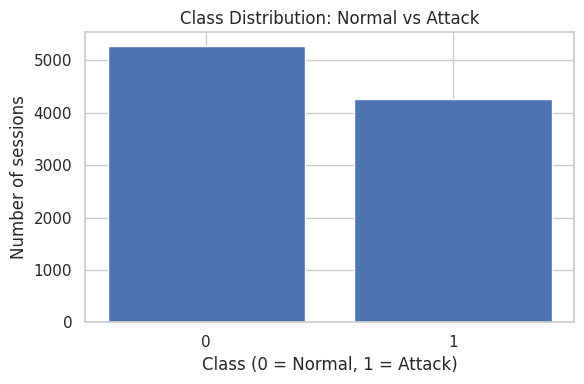

In [41]:
class_counts = working[TARGET_COLUMN].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title('Class Distribution: Normal vs Attack')
plt.xlabel('Class (0 = Normal, 1 = Attack)')
plt.ylabel('Number of sessions')
plt.tight_layout()
plt.show()

In [42]:
# One-hot encode categorical predictors for correlation analysis only.
# This is descriptive EDA; model preprocessing is fit separately on training data.
eda_features = working[num_cols + cat_cols].copy()
for col in cat_cols:
    eda_features[col] = eda_features[col].fillna('Missing').astype(str)
eda_encoded = pd.get_dummies(eda_features, columns=cat_cols, dtype=int)
correlations = eda_encoded.corrwith(working[TARGET_COLUMN]).dropna()
top_corr = correlations.loc[correlations.abs().sort_values(ascending=False).index].head(10)
print('Encoded feature count:', len(correlations))
display(top_corr.to_frame('Pearson correlation with attack_detected'))

Encoded feature count: 17


,Pearson correlation with attack_detected
failed_logins,0.363726
login_attempts,0.277320
ip_reputation_score,0.211540
browser_type_Unknown,0.134630
session_duration,0.041602
browser_type_Chrome,-0.040087
encryption_used_AES,-0.020693
protocol_type_ICMP,-0.016619
encryption_used_Missing,0.016161
browser_type_Safari,-0.013289


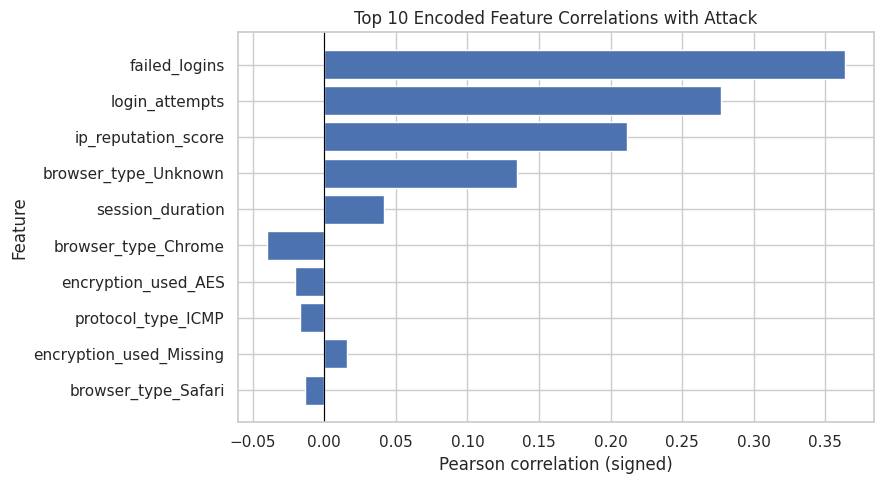

In [43]:
plt.figure(figsize=(9, 5))
plt.barh(top_corr.index, top_corr.values)
plt.gca().invert_yaxis()
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 10 Encoded Feature Correlations with Attack')
plt.xlabel('Pearson correlation (signed)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Note:** The dataset has six numerical and three categorical original predictors. Categorical predictors are one-hot encoded **for EDA only**, allowing the ten strongest encoded-feature correlations to be displayed. This does not change the model training pipeline.

## 4. Train Models
Each model contains its own preprocessing pipeline. Metrics below treat Attack (`1`) as the positive class.

In [44]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
}
print('Models:', list(models))

Models: ['Decision Tree', 'KNN (k=5)', 'Logistic Regression']


In [45]:
trained_models = {}
predictions = {}
for name, classifier in models.items():
    model = Pipeline([('preprocessor', preprocessor), ('classifier', classifier)])
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)
    print('Trained:', name)

Trained: Decision Tree
Trained: KNN (k=5)
Trained: Logistic Regression


In [46]:
def calculate_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

In [47]:
comparison_df = pd.DataFrame({
    name: calculate_metrics(y_test, pred)
    for name, pred in predictions.items()
}).T
print('Model performance on held-out test set:')
display(comparison_df.round(4))

Model performance on held-out test set:


,Accuracy,Precision,Recall,F1
Decision Tree,0.8213,0.8070,0.7890,0.7979
KNN (k=5),0.8008,0.8690,0.6530,0.7456
Logistic Regression,0.7285,0.7173,0.6483,0.6810


## 5. Decision Tree Depth Tuning

Evaluate `max_depth = [3, 5, 10, 15, 20, None]` using stratified 5-fold cross-validation on **training data only**. Show mean Accuracy, Precision, Recall and F1 for each depth; select the best depth using cross-validated F1. The test set remains held out until final evaluation.

In [48]:
depths = [3, 5, 10, 15, 20, None]
min_class_count = y_train.value_counts().min()
n_splits = min(5, int(min_class_count))
assert n_splits >= 2, 'Need at least two training samples in each class.'
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

In [49]:
from sklearn.model_selection import cross_validate

depth_results = []
for depth in depths:
    tree_pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    ])
    scores = cross_validate(
        tree_pipe, X_train, y_train, cv=cv,
        scoring={'Accuracy': 'accuracy', 'Precision': 'precision',
                 'Recall': 'recall', 'F1': 'f1'},
        n_jobs=1
    )
    depth_results.append({
        'max_depth': str(depth),
        'CV Accuracy': scores['test_Accuracy'].mean(),
        'CV Precision': scores['test_Precision'].mean(),
        'CV Recall': scores['test_Recall'].mean(),
        'CV F1 Mean': scores['test_F1'].mean(),
        'CV F1 Std': scores['test_F1'].std()
    })

In [50]:
depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))

,max_depth,CV Accuracy,CV Precision,CV Recall,CV F1 Mean,CV F1 Std
0,3,0.8738,1.0000,0.7177,0.8355,0.0131
1,5,0.8942,1.0000,0.7634,0.8657,0.0112
2,10,0.8916,0.9824,0.7713,0.8641,0.0118
3,15,0.8730,0.9243,0.7801,0.8460,0.0155
4,20,0.8481,0.8557,0.7951,0.8241,0.0159
5,None,0.8153,0.7849,0.8089,0.7966,0.0129


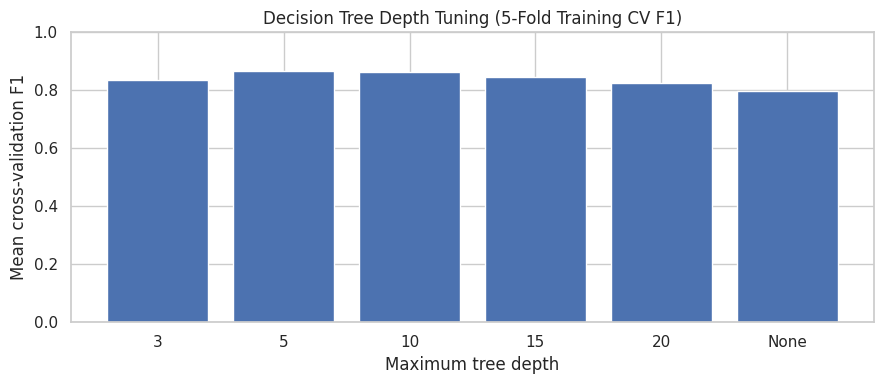

In [51]:
plt.figure(figsize=(9, 4))
plt.bar(depth_df['max_depth'], depth_df['CV F1 Mean'])
plt.title('Decision Tree Depth Tuning (5-Fold Training CV F1)')
plt.xlabel('Maximum tree depth')
plt.ylabel('Mean cross-validation F1')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [52]:
best_row = depth_df.loc[depth_df['CV F1 Mean'].idxmax()]
best_depth = None if best_row['max_depth'] == 'None' else int(best_row['max_depth'])
print('Best depth from training CV:', best_depth)

Best depth from training CV: 5


In [53]:
best_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE))
])
best_tree.fit(X_train, y_train)
best_tree_pred = best_tree.predict(X_test)
print('Tuned Decision Tree test metrics:')
display(pd.DataFrame([calculate_metrics(y_test, best_tree_pred)]).round(4))

Tuned Decision Tree test metrics:


,Accuracy,Precision,Recall,F1
0,0.8842,1.0,0.7409,0.8512


## 6. Evaluate All Three Models

In [54]:
for name, pred in predictions.items():
    print('\n' + '=' * 55)
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=['Normal (0)', 'Attack (1)'],
                                zero_division=0))


Decision Tree
              precision    recall  f1-score   support

  Normal (0)       0.83      0.85      0.84      1055
  Attack (1)       0.81      0.79      0.80       853

    accuracy                           0.82      1908
   macro avg       0.82      0.82      0.82      1908
weighted avg       0.82      0.82      0.82      1908


KNN (k=5)
              precision    recall  f1-score   support

  Normal (0)       0.77      0.92      0.84      1055
  Attack (1)       0.87      0.65      0.75       853

    accuracy                           0.80      1908
   macro avg       0.82      0.79      0.79      1908
weighted avg       0.81      0.80      0.80      1908


Logistic Regression
              precision    recall  f1-score   support

  Normal (0)       0.74      0.79      0.76      1055
  Attack (1)       0.72      0.65      0.68       853

    accuracy                           0.73      1908
   macro avg       0.73      0.72      0.72      1908
weighted avg       0.73    

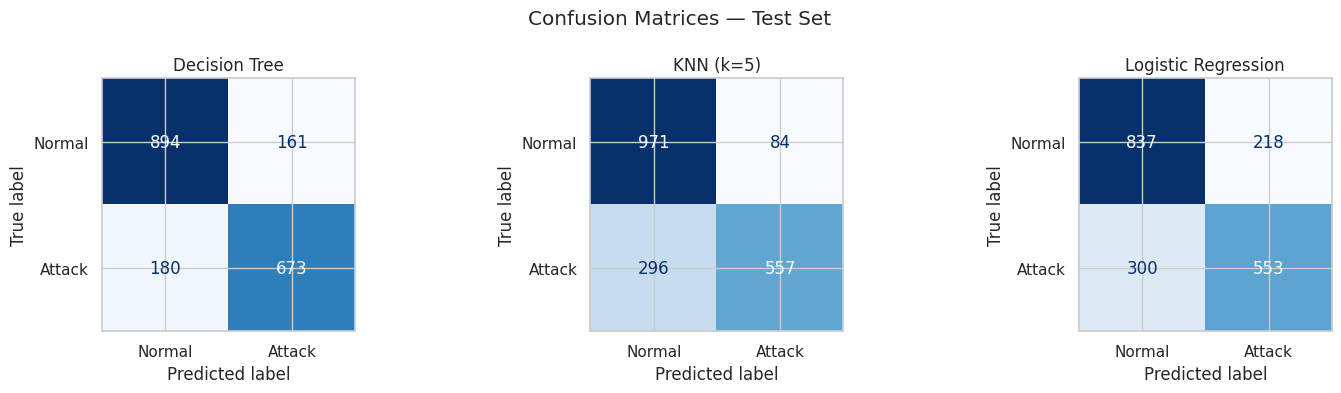

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Attack']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(name)
plt.suptitle('Confusion Matrices — Test Set')
plt.tight_layout()
plt.show()

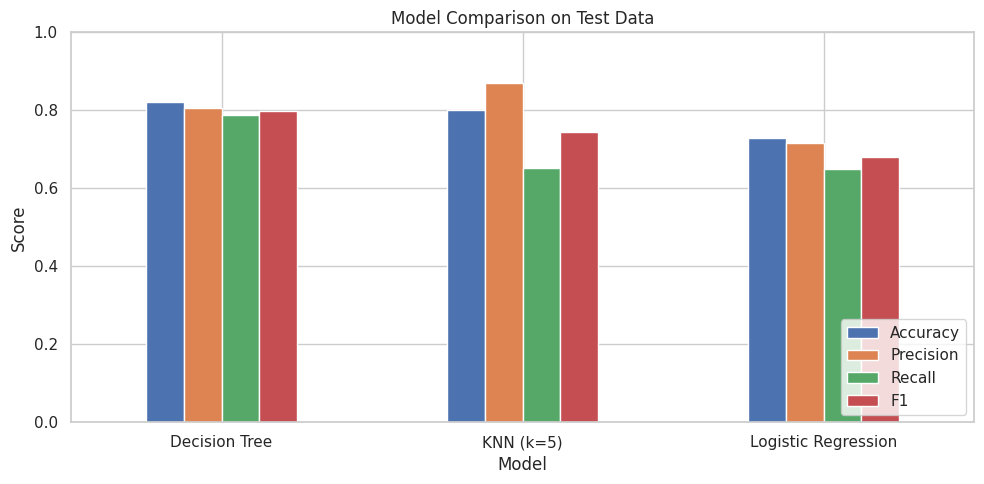

In [56]:
comparison_df.plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title('Model Comparison on Test Data')
plt.ylabel('Score')
plt.xlabel('Model')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()